# 04 - Baseline, Model Training and Model Selection

**Goal:** compare several models *fairly*, using only the development set, and choose one with a rule written down in advance.

## The models and why each is here
| Model | What it does (intuition) | Why included | Strengths | Limitations |
|---|---|---|---|---|
| **Dummy (prior)** | Always outputs the base rate (26.5%) | **Baseline**: the floor any real model must beat. Also shows how deceptive accuracy is (always saying "stays" is ~73.5% accurate). | Trivial, honest | Learns nothing |
| **Logistic Regression** | Weighted sum of features -> squashed to a probability with the sigmoid: `p = 1/(1+exp(-(b0 + b.x)))`. Fitted by maximising likelihood (with L2 penalty). | Simple, fast, interpretable, usually well calibrated; a strong benchmark for tabular data | Coefficients readable; stable | Only linear in the (transformed) inputs; interactions must be hand-made |
| **Random Forest** | Many decision trees on random subsets of rows/columns; average their votes (bagging) | Captures non-linearity/interactions with little tuning | Robust, few hyper-parameters | Large, probabilities can be less sharp; no extrapolation |
| **XGBoost** | Trees built *sequentially*; each new tree fits the errors (gradient of the loss) of the ensemble so far (boosting) | Often best on tabular data | Accurate, regularised, fast | Many hyper-parameters; can overfit; harder to explain |
| **LightGBM** | Boosting with histogram binning and leaf-wise tree growth | Same family, usually faster | Fast, accurate | Leaf-wise growth overfits small data unless `num_leaves`/`min_child_samples` are constrained |

> **We do not assume complex models win.** On small, mostly-categorical tabular data a regularised linear model is often just as good.

## Cross-validation in one paragraph
**Stratified 5-fold CV:** split the development set into 5 parts that each keep the 26.5% churn rate. Train on 4, score on the 5th, rotate 5 times, average. Every customer is used for validation exactly once, so the score uses all the data yet never scores a model on rows it trained on.
The **standard deviation across folds** tells us how noisy the estimate is - differences smaller than that noise are not trustworthy.

## Selection criterion (stated before looking at results)
1. **Primary metric: PR-AUC (average precision)** - threshold-free, focused on the churn class, and sensitive to imbalance (the no-skill value is the prevalence, 0.265, not 0.5). ROC-AUC and Brier score are secondary checks.
2. **One-standard-error rule:** among models whose PR-AUC is within one standard error of the best, choose the **simplest**. This avoids crowning the winner of a noisy race.
3. The decision threshold is a *separate* later decision (notebook 05); it must not influence model choice.

In [1]:
import sys, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))                       # lets notebooks import the src/ package

import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from src import config

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 60); pd.set_option("display.width", 170)
config.FIGURES_DIR.mkdir(parents=True, exist_ok=True)

def savefig(name):
    """Save the current figure into reports/figures (used by README and dashboard)."""
    plt.savefig(config.FIGURES_DIR / name, dpi=150, bbox_inches="tight")

In [2]:
from src.data_preprocessing import load_split, split_xy
from src.train import run_default_cv, select_model, get_model_specs
X, y = split_xy(load_split("train"))
default = run_default_cv(X, y, feature_set="base")            # ~20 seconds
show = default[["model", "average_precision_mean", "average_precision_std", "roc_auc_mean", "neg_brier_mean", "accuracy_mean", "precision_mean", "recall_mean", "f1_mean"]].copy()
show["brier"] = -show.pop("neg_brier_mean")
display(show.round(3))

,model,average_precision_mean,average_precision_std,roc_auc_mean,accuracy_mean,precision_mean,recall_mean,f1_mean,brier
0,Dummy (prior),0.265,0.000,0.500,0.735,0.000,0.000,0.000,0.195
1,LogisticRegression,0.661,0.022,0.846,0.802,0.652,0.544,0.592,0.135
2,RandomForest,0.659,0.024,0.845,0.803,0.676,0.497,0.573,0.135
3,LightGBM,0.653,0.023,0.841,0.794,0.640,0.514,0.570,0.138
4,XGBoost,0.667,0.022,0.847,0.804,0.667,0.524,0.586,0.134
5,LogisticRegression (balanced),0.660,0.022,0.846,0.748,0.517,0.801,0.628,0.165


**Metrics above `precision/recall/f1/accuracy` use the default 0.5 cut-off; PR-AUC, ROC-AUC and Brier do not depend on any threshold.**
Look at the Dummy row: accuracy 0.735 with precision, recall and F1 of 0. It "wins" on accuracy against many real models while being useless - the first reason accuracy is not our selection metric.

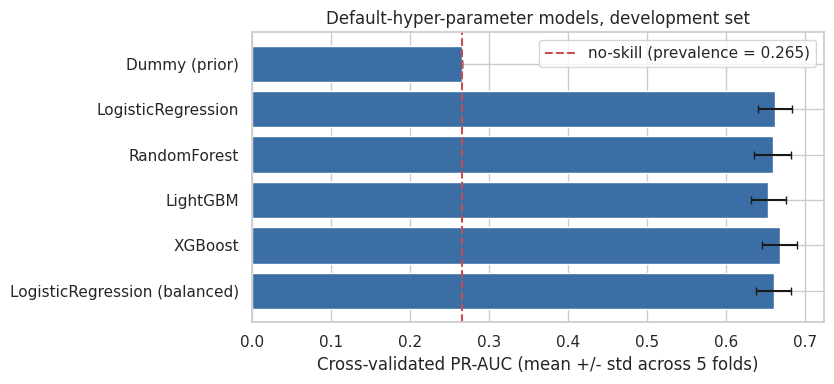

In [3]:
fig, ax = plt.subplots(figsize=(8.5, 4))
d = default.iloc[::-1]
ax.barh(d.model, d.average_precision_mean, xerr=d.average_precision_std, color="#3b6ea5", capsize=3)
ax.axvline(y.mean(), c="C3", ls="--", label=f"no-skill (prevalence = {y.mean():.3f})")
ax.set(xlabel="Cross-validated PR-AUC (mean +/- std across 5 folds)", title="Default-hyper-parameter models, development set"); ax.legend(); plt.tight_layout(); savefig("model_cv_default_pr_auc.png")

## Overfitting check: training score vs validation score
A big gap means the model memorises training data. (Training score = score on the same folds' training portion.)

In [4]:
gap = default[["model", "train_average_precision_mean", "average_precision_mean"]].rename(columns={"train_average_precision_mean": "PR-AUC on training folds", "average_precision_mean": "PR-AUC on validation folds"})
gap["gap"] = gap.iloc[:, 1] - gap.iloc[:, 2]
display(gap.round(3))

,model,PR-AUC on training folds,PR-AUC on validation folds,gap
0,Dummy (prior),0.265,0.265,-0.000
1,LogisticRegression,0.667,0.661,0.006
2,RandomForest,0.836,0.659,0.177
3,LightGBM,0.852,0.653,0.199
4,XGBoost,0.749,0.667,0.082
5,LogisticRegression (balanced),0.665,0.660,0.005


**Reading it.** Logistic Regression has almost no gap (it is too constrained to memorise). The default Random Forest and LightGBM fit the training folds extremely well (training PR-AUC about 0.84-0.85) but score only ~0.65 on validation: **classic overfitting**. This is exactly why we tune the tree models' complexity (leaves, minimum samples per leaf, regularisation) rather than accept defaults.

## Tuning without fooling ourselves: nested cross-validation
If we tune hyper-parameters with CV and then report that same CV score, the score is optimistic (we picked the best of many tries *on those folds*).
**Nested CV** fixes this: for each of 5 *outer* folds, a small random search (3-fold *inner* CV, 8-12 candidate settings) picks hyper-parameters using only the outer-training part, and the outer-validation fold scores the tuned model. The average outer score estimates the performance of the whole *procedure* "tune, then fit".
`python -m src.train` already ran this (it takes a few minutes on one CPU core); we load the saved results.

In [5]:
nested = pd.read_csv(config.CV_NESTED_PATH); folds = pd.read_csv(config.CV_FOLDS_PATH)
n_show = nested[["model", "average_precision_mean", "average_precision_std", "roc_auc_mean", "neg_brier_mean", "complexity"]].copy()
n_show["brier"] = -n_show.pop("neg_brier_mean"); display(n_show.round(4))
chosen, rule = select_model(nested); print("Selection:", rule)

,model,average_precision_mean,average_precision_std,roc_auc_mean,complexity,brier
0,Dummy (prior),0.2654,0.0001,0.5000,0,0.1949
1,LogisticRegression,0.6604,0.0190,0.8458,1,0.1352
2,RandomForest,0.6602,0.0237,0.8467,2,0.1349
3,LightGBM,0.6729,0.0225,0.8500,3,0.1332
4,XGBoost,0.6680,0.0225,0.8492,3,0.1339


Selection: highest CV PR-AUC (LightGBM, 0.6729); within 1 SE (0.0101) -> ['LightGBM', 'XGBoost']; simplest chosen -> LightGBM


model,Dummy (prior),LogisticRegression,RandomForest,XGBoost,LightGBM
fold,,,,,
0,0.2653,0.6456,0.6386,0.6554,0.6571
1,0.2653,0.6374,0.6324,0.6350,0.6421
2,0.2653,0.6823,0.6882,0.6901,0.6968
3,0.2653,0.6752,0.6700,0.6817,0.6863
4,0.2655,0.6614,0.6717,0.6778,0.6821


,mean diff vs LogReg,std of diff,folds better than LogReg
RandomForest,-0.000184,0.007803,2/5
XGBoost,0.007624,0.006803,4/5
LightGBM,0.012516,0.005825,5/5


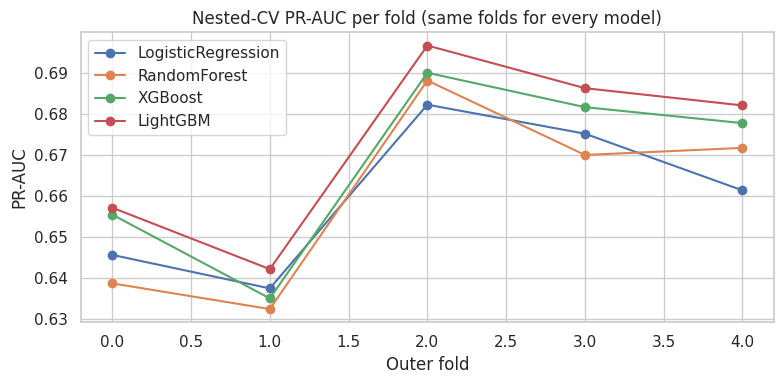

In [6]:
# Per-fold PR-AUC: models are scored on the SAME outer folds, so differences can be examined as paired comparisons
pivot = folds.pivot(index="fold", columns="model", values="average_precision")[["Dummy (prior)", "LogisticRegression", "RandomForest", "XGBoost", "LightGBM"]]
display(pivot.round(4))
paired = pd.DataFrame({m: {"mean diff vs LogReg": (pivot[m] - pivot["LogisticRegression"]).mean(), "std of diff": (pivot[m] - pivot["LogisticRegression"]).std(ddof=1),
                           "folds better than LogReg": f"{int((pivot[m] > pivot['LogisticRegression']).sum())}/5"} for m in ["RandomForest", "XGBoost", "LightGBM"]}).T
display(paired.round(4))
fig, ax = plt.subplots(figsize=(8, 4))
for m in pivot.columns[1:]: ax.plot(pivot.index, pivot[m], marker="o", label=m)
ax.set(xlabel="Outer fold", ylabel="PR-AUC", title="Nested-CV PR-AUC per fold (same folds for every model)"); ax.legend(); plt.tight_layout(); savefig("model_nested_cv_per_fold.png")

## What the selection tells us (read from the actual results above)
* **All real models beat the baseline by a wide margin** (PR-AUC about 0.66-0.67 vs 0.265; ROC-AUC about 0.85 vs 0.50). There is genuine predictive signal in the data.
* **The models are close.** Logistic Regression and Random Forest tie at ~0.660, XGBoost is 0.668 and LightGBM 0.673. The gap between best and worst real model (0.013) is smaller than the fold-to-fold standard deviation (~0.02).
* **Rule outcome:** LightGBM has the best mean; XGBoost is within one standard error (0.010); Logistic Regression and Random Forest fall just outside it. LightGBM and XGBoost have the same complexity rank, so the higher mean (LightGBM) is chosen.
* **Honesty check - how convincing is the win?** LightGBM beats Logistic Regression in all 5 outer folds, by +0.012 PR-AUC on average, with per-fold gains ranging from about +0.005 to +0.021, so this is a *consistent but small* edge, not a dramatic one (and the folds share data, so even 5/5 is weaker evidence than it sounds). A reasonable analyst could prefer Logistic Regression for its simplicity and transparency; the project documents this trade-off rather than hiding it.
* **What tuning did:** the winning configuration is heavily regularised (very few leaves per tree, large minimum leaf size) - the opposite of the overfitting default.
* **Class weighting** (earlier notebook) was rejected because it distorts probabilities (Brier 0.165 vs 0.135) for no ranking gain.

## Final fit
`python -m src.train` re-runs the search once on the *whole* development set, fits the final model, and stores it in `models/churn_model.joblib` with the chosen hyper-parameters in `models/model_metadata.json`.

In [7]:
import json
meta = json.loads(config.METADATA_PATH.read_text())
print("Final model:", meta["model_name"], "| feature set:", meta["feature_set"])
print("Selected hyper-parameters:", json.dumps(meta["best_params"], indent=2))

Final model: LightGBM | feature set: base
Selected hyper-parameters: {
  "model__reg_lambda": 5,
  "model__num_leaves": 4,
  "model__n_estimators": 200,
  "model__min_child_samples": 80,
  "model__learning_rate": 0.05,
  "model__colsample_bytree": 0.5
}


## What to remember / interview questions
* *"Why a baseline?"* - It defines what "no skill" looks like; without it an accuracy of 73.5% might look good when it is achievable by always predicting "stays".
* *"How does k-fold CV work and why stratify?"* - Rotate which fold is held out; stratification keeps the class ratio equal in every fold, important for imbalanced targets.
* *"Why can't I report the best CV score from my grid search as my final performance?"* - Selection bias: the maximum of many noisy estimates is optimistic; use nested CV or a separate untouched test set.
* *"Why might logistic regression match gradient boosting here?"* - Mostly categorical features with few strong, roughly additive effects, ~5.6k rows: little for flexible models to exploit beyond what a linear model already captures.
* *"Boosting vs bagging?"* - Bagging averages independent deep-ish trees to cut variance; boosting adds shallow trees sequentially to cut bias.